In [ ]:
pip install pgmpy networkx matplotlib pandas numpy

In [1]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import BayesianEstimator
from pgmpy.sampling import BayesianModelSampling
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [ ]:
import sys
print(sys.executable)

In [3]:
# -----------------------------------------------------------
# 1. NETWORK STRUCTURE
# -----------------------------------------------------------

air_model = DiscreteBayesianNetwork([
    ('Traffic', 'AQI'),
    ('Industry', 'AQI'),
    ('Temperature', 'AQI'),
    ('Humidity', 'AQI'),
    ('AQI', 'Respiratory')
])

In [4]:
# -----------------------------------------------------------
# 2. CPDs
# -----------------------------------------------------------

traffic_cpd = TabularCPD(
    variable='Traffic', variable_card=3,
    values=[[0.3], [0.4], [0.3]],
    state_names={'Traffic': ['Low', 'Medium', 'High']}
)

industry_cpd = TabularCPD(
    variable='Industry', variable_card=3,
    values=[[0.25], [0.5], [0.25]],
    state_names={'Industry': ['Low', 'Medium', 'High']}
)

temp_cpd = TabularCPD(
    variable='Temperature', variable_card=3,
    values=[[0.3], [0.4], [0.3]],
    state_names={'Temperature': ['Cool', 'Warm', 'Hot']}
)

humidity_cpd = TabularCPD(
    variable='Humidity', variable_card=3,
    values=[[0.3], [0.4], [0.3]],
    state_names={'Humidity': ['Low', 'Medium', 'High']}
)

In [5]:
# Dynamically build CPT for AQI based on pollution scoring logic
aqi_good = []
aqi_mod = []
aqi_poor = []

for t in ['Low','Medium','High']:
    for ind in ['Low','Medium','High']:
        for tm in ['Cool','Warm','Hot']:
            for h in ['Low','Medium','High']:

                score = 0
                score += {'Low':0.1,'Medium':0.4,'High':0.7}[t]
                score += {'Low':0.1,'Medium':0.5,'High':0.8}[ind]
                score += {'Cool':0.1,'Warm':0.4,'Hot':0.6}[tm]
                score += {'Low':0.1,'Medium':0.4,'High':0.6}[h]

                if score < 1.0:
                    aqi_good.append(1.0)
                    aqi_mod.append(0.0)
                    aqi_poor.append(0.0)
                elif score < 1.8:
                    aqi_good.append(0.0)
                    aqi_mod.append(1.0)
                    aqi_poor.append(0.0)
                else:
                    aqi_good.append(0.0)
                    aqi_mod.append(0.0)
                    aqi_poor.append(1.0)

In [6]:
aqi_cpd = TabularCPD(
    variable='AQI', variable_card=3,
    values=[aqi_good, aqi_mod, aqi_poor],
    evidence=['Traffic','Industry','Temperature','Humidity'],
    evidence_card=[3,3,3,3],
    state_names={
        'AQI':['Good','Moderate','Poor'],
        'Traffic':['Low','Medium','High'],
        'Industry':['Low','Medium','High'],
        'Temperature':['Cool','Warm','Hot'],
        'Humidity':['Low','Medium','High']
    }
)

resp_cpd = TabularCPD(
    variable='Respiratory', variable_card=3,
    values=[
        [0.75, 0.30, 0.15],  # Low
        [0.20, 0.50, 0.35],  # Medium
        [0.05, 0.20, 0.50]   # High
    ],
    evidence=['AQI'],
    evidence_card=[3],
    state_names={
        'Respiratory': ['Low','Medium','High'],
        'AQI': ['Good','Moderate','Poor']
    }
)

air_model.add_cpds(traffic_cpd, industry_cpd, temp_cpd, humidity_cpd, aqi_cpd, resp_cpd)

print("Model check:", air_model.check_model())

Model check: True


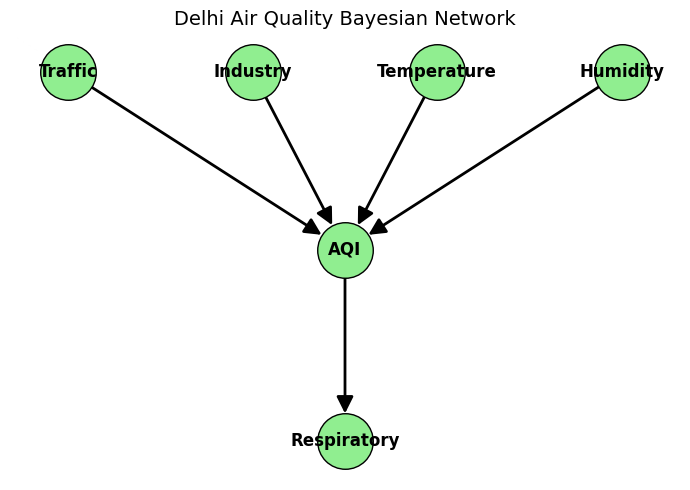

In [7]:
# -----------------------------------------------------------
# 3. DRAW NETWORK
# -----------------------------------------------------------

graph = nx.DiGraph()
graph.add_edges_from([
    ('Traffic', 'AQI'),
    ('Industry', 'AQI'),
    ('Temperature', 'AQI'),
    ('Humidity', 'AQI'),
    ('AQI', 'Respiratory')
])

pos = {
    'Traffic': (0, 3),
    'Industry': (4, 3),
    'Temperature': (8, 3),
    'Humidity': (12, 3),
    'AQI': (6, 1.7),
    'Respiratory': (6, 0.3)
}

plt.figure(figsize=(7, 5))
nx.draw_networkx_nodes(graph, pos, node_color='lightgreen', node_size=1600, edgecolors='black')
nx.draw_networkx_labels(graph, pos, font_size=12, font_weight='bold')
nx.draw_networkx_edges(
    graph, pos, arrows=True, arrowstyle='-|>', arrowsize=25, width=2, node_size=1600
)
plt.title("Delhi Air Quality Bayesian Network", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()


In [8]:
# -----------------------------------------------------------
# 4. INFERENCE
# -----------------------------------------------------------

infer = VariableElimination(air_model)

print("\nP(AQI = Good | Traffic = Low):")
print(infer.query(['AQI'], evidence={'Traffic': 'Low'}))

print("\nP(Respiratory = Low | AQI = Good):")
print(infer.query(['Respiratory'], evidence={'AQI': 'Good'}))

print("\nP(AQI = Poor | Industry = High, Temperature = Hot):")
print(infer.query(['AQI'], evidence={'Industry': 'High', 'Temperature': 'Hot'}))

print("\nP(Respiratory = High | Traffic = High, Humidity = High):")
print(infer.query(['Respiratory'], evidence={'Traffic': 'High', 'Humidity': 'High'}))



P(AQI = Good | Traffic = Low):
+---------------+------------+
| AQI           |   phi(AQI) |
+===============+============+
| AQI(Good)     |     0.1725 |
+---------------+------------+
| AQI(Moderate) |     0.7450 |
+---------------+------------+
| AQI(Poor)     |     0.0825 |
+---------------+------------+

P(Respiratory = Low | AQI = Good):
+---------------------+--------------------+
| Respiratory         |   phi(Respiratory) |
+=====================+====================+
| Respiratory(Low)    |             0.7500 |
+---------------------+--------------------+
| Respiratory(Medium) |             0.2000 |
+---------------------+--------------------+
| Respiratory(High)   |             0.0500 |
+---------------------+--------------------+

P(AQI = Poor | Industry = High, Temperature = Hot):
+---------------+------------+
| AQI           |   phi(AQI) |
+===============+============+
| AQI(Good)     |     0.0000 |
+---------------+------------+
| AQI(Moderate) |     0.0900 |
+--------

In [10]:
# -----------------------------------------------------------
# 5. SAMPLE GENERATION
# -----------------------------------------------------------

print("\nGenerating 2000 synthetic samples...")
sampler = BayesianModelSampling(air_model)
data = sampler.forward_sample(size=2000)
print(data.head())



Generating 2000 synthetic samples...


  0%|          | 0/6 [00:00<?, ?it/s]

  Traffic       AQI Industry Temperature Humidity Respiratory
0  Medium      Poor   Medium        Warm     High        High
1    High      Poor   Medium        Warm   Medium        High
2     Low  Moderate   Medium         Hot   Medium         Low
3  Medium  Moderate   Medium         Hot      Low      Medium
4    High  Moderate   Medium        Cool   Medium         Low


In [11]:
# -----------------------------------------------------------
# 6. PARAMETER LEARNING (FIXED)
# -----------------------------------------------------------

learned_model = DiscreteBayesianNetwork(air_model.edges())

# The fix: supply pseudo_counts=1
learned_model.fit(
    data,
    estimator=BayesianEstimator,
    prior_type="dirichlet",
    pseudo_counts=1
)

print("\nLearned CPD for AQI:")
print(learned_model.get_cpds('AQI'))

print("\nLearned CPD for Respiratory Cases:")
print(learned_model.get_cpds('Respiratory'))

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Traffic': 'C', 'AQI': 'C', 'Industry': 'C', 'Temperature': 'C', 'Humidity': 'C', 'Respiratory': 'C'}



Learned CPD for AQI:
+---------------+-----+----------------------+
| Humidity      | ... | Humidity(Medium)     |
+---------------+-----+----------------------+
| Industry      | ... | Industry(Medium)     |
+---------------+-----+----------------------+
| Temperature   | ... | Temperature(Warm)    |
+---------------+-----+----------------------+
| Traffic       | ... | Traffic(Medium)      |
+---------------+-----+----------------------+
| AQI(Good)     | ... | 0.016666666666666666 |
+---------------+-----+----------------------+
| AQI(Moderate) | ... | 0.9666666666666667   |
+---------------+-----+----------------------+
| AQI(Poor)     | ... | 0.016666666666666666 |
+---------------+-----+----------------------+

Learned CPD for Respiratory Cases:
+---------------------+-----+--------------------+
| AQI                 | ... | AQI(Poor)          |
+---------------------+-----+--------------------+
| Respiratory(High)   | ... | 0.5251141552511416 |
+---------------------+-----+----

In [12]:
# -----------------------------------------------------------
# 7. INTERVENTION: do(Traffic = Low)
# -----------------------------------------------------------

def do_intervention(model, var, value):
    m = model.copy()
    for parent in m.get_parents(var):
        m.remove_edge(parent, var)

    fake = data.copy()
    fake[var] = value

    m.fit(fake, estimator=BayesianEstimator, prior_type="dirichlet", pseudo_counts=1)
    return m

do_model = do_intervention(air_model, 'Traffic', 'Low')
do_infer = VariableElimination(do_model)

print("\nP(Respiratory = Low | do(Traffic = Low)):")
print(do_infer.query(['Respiratory']))


INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'Traffic': 'C', 'AQI': 'C', 'Industry': 'C', 'Temperature': 'C', 'Humidity': 'C', 'Respiratory': 'C'}



P(Respiratory = Low | do(Traffic = Low)):
+---------------------+--------------------+
| Respiratory         |   phi(Respiratory) |
+=====================+====================+
| Respiratory(High)   |             0.2943 |
+---------------------+--------------------+
| Respiratory(Low)    |             0.2873 |
+---------------------+--------------------+
| Respiratory(Medium) |             0.4184 |
+---------------------+--------------------+
